# Importing Required Libraries

In [26]:
# the major libraries used are numpy, pandas, matplotlib, seaborn and scikit-learn
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

RANDOM_STATE     = 42
DATA_PATH        = "raw_student_performance_data.csv"
CGPA_THRESHOLD   = 3.0
PLACEHOLDER_SGPA = 2.68
PLACEHOLDER_CGPA = 3.15
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

# Loading & Displaying Raw Data

In [27]:
# handling the FileNotFoundError in case the file wasn't found at the specified location
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig") # loading the raw data into python

# cleaning up column names by removing any leading or trailing whitespace using ".strip()" method
df_raw.columns = [c.strip() for c in df_raw.columns]

print("=" * 80)
print(" RAW DATA PROFILE")
print("=" * 80)

# displaying the dimsensions of the raw data (number of rows, number of columns) using the ".shape" attribute
print(f"Shape            : {df_raw.shape}")
print(f"Columns ({len(df_raw.columns)}):")

# displaying all columns in the raw data file using a for loop
for c in df_raw.columns:
    print("   -", c)

# displaying the first five records using the ".head()" method
print("\nFirst 5 records:")
print(df_raw.head())

 RAW DATA PROFILE
Shape            : (1194, 31)
Columns (31):
   - University Admission year
   - Gender
   - Age
   - H.S.C passing year
   - Program
   - Current Semester
   - Do you have meritorious scholarship ?
   - Do you use University transportation?
   - How many hour do you study daily?
   - How many times do you seat for study in a day?
   - What is your preferable learning mode?
   - Do you use smart phone?
   - Do you have personal Computer?
   - How many hour do you spent daily in social media?
   - Status of your English language proficiency
   - Average attendance on class
   - Did you ever fall in probation?
   - Did you ever got suspension?
   - Do you attend in teacher consultancy for any kind of academical problems?
   - What are the skills do you have ?
   - How many hour do you spent daily on your skill development?
   - What is you interested area?
   - What is your relationship status?
   - Are you engaged with any co-curriculum activities?
   - With whom you ar

# Renaming Column Headings

In [28]:
# renaming columns
# this dictionary maps existing column heading to appropriate variable names
col_map = {
    'University Admission year'                                          : 'admission_year',
    'Gender'                                                             : 'gender',
    'Age'                                                                : 'age',
    'H.S.C passing year'                                                 : 'hsc_year',
    'Program'                                                            : 'program',
    'Current Semester'                                                   : 'semester',
    'Do you have meritorious scholarship ?'                              : 'scholarship',
    'Do you use University transportation?'                              : 'transport',
    'How many hour do you study daily?'                                  : 'study_hours',
    'How many times do you seat for study in a day?'                     : 'study_sessions',
    'What is your preferable learning mode?'                             : 'learning_mode',
    'Do you use smart phone?'                                            : 'smartphone',
    'Do you have personal Computer?'                                     : 'computer',
    'How many hour do you spent daily in social media?'                  : 'social_media_hours',
    'Status of your English language proficiency'                        : 'english_level',
    'Average attendance on class'                                        : 'attendance',
    'Did you ever fall in probation?'                                    : 'probation',
    'Did you ever got suspension?'                                       : 'suspension',
    'Do you attend in teacher consultancy for any kind of academical problems?': 'consultancy',
    'What are the skills do you have ?'                                  : 'skills',
    'How many hour do you spent daily on your skill development?'        : 'skill_hours',
    'What is you interested area?'                                       : 'interest_area',
    'What is your relationship status?'                                  : 'relationship',
    'Are you engaged with any co-curriculum activities?'                 : 'cocurriculum',
    'With whom you are living with?'                                     : 'living_with',
    'Do you have any health issues?'                                     : 'health_issues',
    'What was your previous SGPA?'                                       : 'prev_sgpa',
    'Do you have any physical disabilities?'                             : 'disability',
    'What is your current CGPA?'                                         : 'current_cgpa',
    'How many Credit did you have completed?'                            : 'credits_completed',
    'What is your monthly family income?'                                : 'family_income',
}

# creating a new dataframe with renamed column headings using the ".rename()" and ".copy()" methods
# the new datafram "df" is a copy of the original "df_raw", and changes made to it don't affect the original
df = df_raw.rename(columns=col_map).copy()

# Preparing Raw Data

In [29]:
# converting yes/no answers to 1/0 and returning NaN for unrecognised values.
def clean_binary(val):

    # checking if a value is already missing
    if pd.isna(val):
        return np.nan

    # converting values to strings and removing whitespace
    s = str(val).strip().lower()
    if s in {'yes', 'y', '1', 'true'}:
        return 1
    if s in {'no', 'n', '0', 'false'}:
        return 0
    return np.nan


# Parses attendance values, turns ranges like '94-98' into the midpoint 96.0 and plain numbers into floats.
def parse_attendance(val):

    # checking if a value is already missing
    if pd.isna(val):
        return np.nan

    # converting value to string and removing whitespace
    s = str(val).strip()

    # checking for, and converting numeric like ranges into the midpoint of the range
    if '-' in s:
        try:
            a, b = s.split('-')
            return (float(a) + float(b)) / 2.0
        except ValueError:
            return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan


# grouping free-text answers into categories
def clean_skills(val):
    if pd.isna(val): # check if value already missing
        return 'None'
    s = str(val).strip().lower()

    # checking id s contains any of the phrases in the list and returning 'None'
    if any(k in s for k in ["nothing", "don't", "do not", "not any",
                             "no skill", "none", "not yet", "haven't",
                             "i don't", "i do not know", "not started"]):
        return 'None'
    if 'machine learning' in s:
        return 'Machine Learning'
    if 'cyber' in s:
        return 'Cyber Security'
    if 'web' in s:
        return 'Web Development'
    if 'network' in s:
        return 'Networking'
    if 'software' in s:
        return 'Software Development'
    if 'graphic' in s or 'design' in s or 'photograph' in s:
        return 'Design / Media'
    if 'content' in s:
        return 'Content Creation'
    if 'program' in s or 'coding' in s or 'python' in s:
        return 'Programming'
    if 'data' in s:
        return 'Data Science'
    if 'database' in s:
        return 'Database'
    return 'Other'


# standardising 'interest area' labels
def clean_interest(val):
    if pd.isna(val):
        return 'Other'
    s = str(val).strip().lower()
    if 'machine learning' in s:
        return 'Machine Learning'
    if 'artificial' in s or s == 'ai':
        return 'Artificial Intelligence'
    if 'data' in s:
        return 'Data Science'
    if 'network' in s:
        return 'Networking'
    if 'software' in s:
        return 'Software'
    if 'web' in s:
        return 'Web Development'
    if 'hardware' in s:
        return 'Hardware'
    if 'ui' in s or 'ux' in s:
        return 'UI/UX'
    if 'cyber' in s or 'syber' in s:
        return 'Cyber Security'
    if 'entrepreneur' in s:
        return 'Entrepreneur'
    return 'Other'


# standardising 'english proficiency' labels
def clean_english(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if 'basic' in s:
        return 'Basic'
    if 'intermediate' in s:
        return 'Intermediate'
    if 'advance' in s:
        return 'Advanced'
    return np.nan


# standardising 'relationship status' labels
def clean_relationship(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if s == 'single':
        return 'Single'
    if s == 'married':
        return 'Married'
    if s == 'engaged':
        return 'Engaged'
    if 'relationship' in s:
        return 'In Relationship'
    return np.nan


# standardising 'living with' labels
def clean_living(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip().lower()
    if 'family' in s:
        return 'Family'
    if 'bachelor' in s or 'hostel' in s:
        return 'Bachelor/Hostel'
    return np.nan


# Cleaning Raw Data

In [30]:
print("\n" + "=" * 80)
print(" DATA CLEANING")
print("=" * 80)
print(f"Rows before cleaning       : {df.shape[0]}")

# applying the custom cleaning function 'clean_binary' to binary columns
binary_cols = ['scholarship', 'transport', 'smartphone', 'computer',
               'probation', 'suspension', 'consultancy',
               'cocurriculum', 'health_issues', 'disability']
for c in binary_cols:
    df[c] = df[c].apply(clean_binary)

# cleaning the attendance column
df['attendance'] = df['attendance'].apply(parse_attendance)

# correcting the datatype of numeric columns
numeric_cols = ['age', 'admission_year', 'hsc_year', 'semester',
                'study_hours', 'study_sessions', 'social_media_hours',
                'skill_hours', 'prev_sgpa', 'current_cgpa',
                'credits_completed', 'family_income']
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# applying other cleaning functions
df['skills']        = df['skills'].apply(clean_skills)
df['interest_area'] = df['interest_area'].apply(clean_interest)
df['english_level'] = df['english_level'].apply(clean_english)
df['relationship']  = df['relationship'].apply(clean_relationship)
df['living_with']   = df['living_with'].apply(clean_living)
df['learning_mode'] = df['learning_mode'].astype(str).str.strip().str.title()

# checking for suspicious/placeholder rows and dropping them
placeholder_mask = (
    np.isclose(df['prev_sgpa'], PLACEHOLDER_SGPA, atol=1e-6) &
    np.isclose(df['current_cgpa'], PLACEHOLDER_CGPA, atol=1e-6)
)
print(f"Placeholder rows detected  : {int(placeholder_mask.sum())}")
df = df.loc[~placeholder_mask].reset_index(drop=True)

before_dup = df.shape[0] # displaying shape of dataframe before duplicates were removed
df = df.drop_duplicates().reset_index(drop=True) # dropping duplicates
print(f"Duplicate rows removed     : {before_dup - df.shape[0]}")
print(f"Rows after cleaning        : {df.shape[0]}")


 DATA CLEANING
Rows before cleaning       : 1194
Placeholder rows detected  : 140
Duplicate rows removed     : 0
Rows after cleaning        : 1054


# Feature Engineering

In [31]:
""" Feature engineering means creating or reshaping the columns (features) in the data so they’re more useful for analysis
or for a machine learning model."""

df['age_at_admission'] = 17 + (df['admission_year'] - df['hsc_year'])
df['years_since_hsc']  = df['admission_year'] - df['hsc_year']
df['study_efficiency'] = df['study_hours'] / (df['study_sessions'].replace(0, np.nan))
df['social_to_study']  = df['social_media_hours'] / (df['study_hours'] + 1)
df['skill_to_study']   = df['skill_hours'] / (df['study_hours'] + 1)
df['attendance_band']  = pd.cut(df['attendance'],
                                 bins=[-1, 60, 75, 90, 101],
                                 labels=['Low', 'Medium', 'High', 'VeryHigh'])

q99 = df['family_income'].quantile(0.99)
df['family_income'] = df['family_income'].clip(upper=q99)


# Defining Target Variable

In [32]:
# the target variable is the feature that will be predicted by the model

df['performs_well'] = (df['current_cgpa'] >= CGPA_THRESHOLD).astype(int)
print("\nTarget distribution (0=At Risk, 1=Good Performer):")
print(df['performs_well'].value_counts())
print(f"Class balance: {df['performs_well'].mean():.3f} positive rate")



Target distribution (0=At Risk, 1=Good Performer):
performs_well
1    704
0    350
Name: count, dtype: int64
Class balance: 0.668 positive rate


# Preparing Features & Target

In [33]:
# exluding the target and other relevant columns from the training dataset
DROP_COLS = ['current_cgpa', 'prev_sgpa', 'credits_completed', 'performs_well']

X = df.drop(columns=DROP_COLS) # defining the features
y = df['performs_well'] # defining the target

# grouping the feature columns by datatype (text, numeric)
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols   = X.select_dtypes(include=[np.number]).columns.tolist()

print("\n" + "=" * 80)
print(" FEATURES SELECTED")
print("=" * 80)
print(f"Numerical   ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical ({len(categorical_cols)}): {categorical_cols}")


 FEATURES SELECTED
Numerical   (25): ['admission_year', 'age', 'hsc_year', 'semester', 'scholarship', 'transport', 'study_hours', 'study_sessions', 'smartphone', 'computer', 'social_media_hours', 'attendance', 'probation', 'suspension', 'consultancy', 'skill_hours', 'cocurriculum', 'health_issues', 'disability', 'family_income', 'age_at_admission', 'years_since_hsc', 'study_efficiency', 'social_to_study', 'skill_to_study']
Categorical (9): ['gender', 'program', 'learning_mode', 'english_level', 'skills', 'interest_area', 'relationship', 'living_with', 'attendance_band']


# Preprocessing Pipeline

In [34]:
# filling missing values with median and standardising features with big ranges
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
]) # numeric pipeline


# filling missing values with most common category in column
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# routing the grouped columns to the right pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])


# Defining Train & Test Sets

In [35]:
# train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"\nTrain size: {X_train.shape} | Test size: {X_test.shape}")


Train size: (843, 34) | Test size: (211, 34)


# Custom Evaluation Functions

In [36]:
# Computes Accuracy, Precision, Recall, F1 and (optionally) ROC-AUC for a model.
def evaluate_model(name, y_true, y_pred, y_proba=None):
    return {
        'Model'    : name,
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall'   : recall_score(y_true, y_pred, zero_division=0),
        'F1'       : f1_score(y_true, y_pred, zero_division=0),
        'AUC'      : roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan
    }

# Draws the confusion matrix of the best model plus overlaid ROC curves for all models.
def plot_confusion_and_roc(models_dict, X_test_, y_test_):
    """Draw confusion matrix for the best model + ROC curves for all models."""
    # Determine best model by AUC on the test set
    aucs = {n: roc_auc_score(y_test_, p.predict_proba(X_test_)[:, 1])
            for n, p in models_dict.items()}
    best_name = max(aucs, key=aucs.get)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    cm = confusion_matrix(y_test_, models_dict[best_name].predict(X_test_))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                ax=axes[0], xticklabels=['At Risk', 'Good'],
                yticklabels=['At Risk', 'Good'])
    axes[0].set_title(f"Confusion Matrix – {best_name}")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    for name, pipe in models_dict.items():
        y_proba = pipe.predict_proba(X_test_)[:, 1]
        fpr, tpr, _ = roc_curve(y_test_, y_proba)
        axes[1].plot(fpr, tpr, label=f"{name} (AUC={aucs[name]:.3f})")
    axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
    axes[1].set_title("ROC Curves")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].legend(loc='lower right')
    plt.tight_layout()
    plt.savefig("evaluation_plots.png", dpi=150)
    plt.show()


# Defining Models

In [37]:
# logistic regression and random forest
models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf',  LogisticRegression(max_iter=2000,
                                    class_weight='balanced',
                                    random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf',  RandomForestClassifier(n_estimators=300,
                                        max_depth=12,
                                        class_weight='balanced',
                                        random_state=RANDOM_STATE,
                                        n_jobs=-1))
    ]),
}


# Training Models

In [38]:
results = []
fitted_models = {}

print("\n" + "=" * 80)
print(" MODEL TRAINING & EVALUATION")
print("=" * 80)

# training, testing and evaluating
for name, pipe in models.items():
    pipe.fit(X_train, y_train) # trains each model

    fitted_models[name] = pipe # saves trained pipeline for reusability in future
    y_pred  = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    # computing accuracy, precision, recall and AUC using custom function
    results.append(evaluate_model(name, y_test, y_pred, y_proba))

    print(f"\n▶ {name}")
    print(classification_report(y_test, y_pred,
                                target_names=['At Risk', 'Good Performer'],
                                zero_division=0))

# displaying results
results_df = pd.DataFrame(results).sort_values('AUC', ascending=False)
print("\n" + "=" * 80)
print(" SUMMARY OF RESULTS")
print("=" * 80)
print(results_df.to_string(index=False))


 MODEL TRAINING & EVALUATION

▶ Logistic Regression
                precision    recall  f1-score   support

       At Risk       0.52      0.60      0.56        70
Good Performer       0.78      0.72      0.75       141

      accuracy                           0.68       211
     macro avg       0.65      0.66      0.65       211
  weighted avg       0.70      0.68      0.69       211


▶ Random Forest
                precision    recall  f1-score   support

       At Risk       0.67      0.46      0.54        70
Good Performer       0.77      0.89      0.82       141

      accuracy                           0.74       211
     macro avg       0.72      0.67      0.68       211
  weighted avg       0.73      0.74      0.73       211


 SUMMARY OF RESULTS
              Model  Accuracy  Precision   Recall       F1      AUC
      Random Forest  0.744076   0.766871 0.886525 0.822368 0.798683
Logistic Regression  0.682464   0.784615 0.723404 0.752768 0.760284


# Cross-Validation

In [39]:
# double-checking the best model's performance
best_name = results_df.iloc[0]['Model']
best_pipe = fitted_models[best_name]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(best_pipe, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
print(f"\n5-fold CV ROC-AUC on {best_name}: "
      f"{cv_auc.mean():.4f} ± {cv_auc.std():.4f}")



5-fold CV ROC-AUC on Random Forest: 0.7451 ± 0.0242


# Visualising Output


Generating plots...


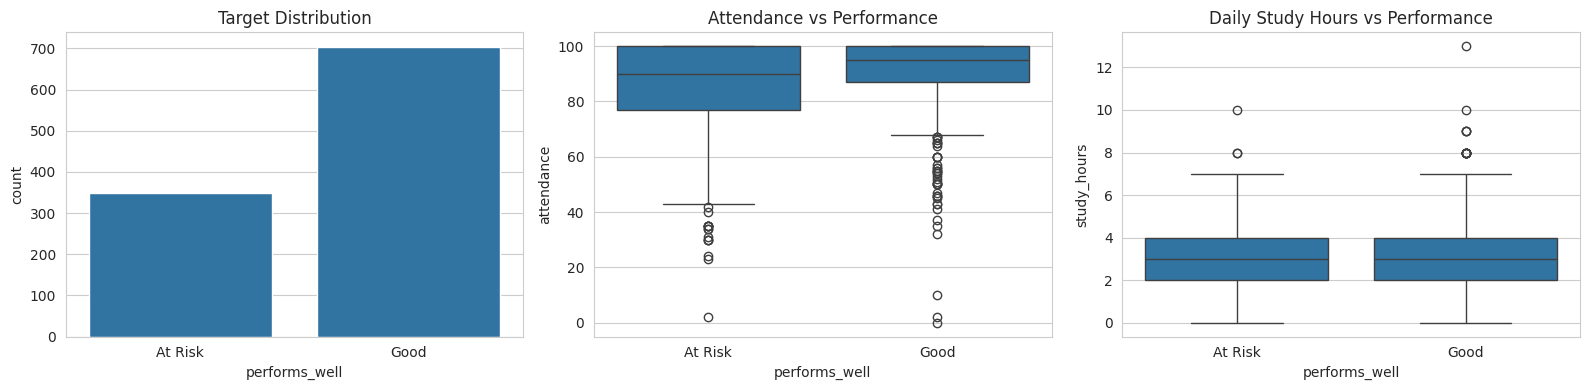

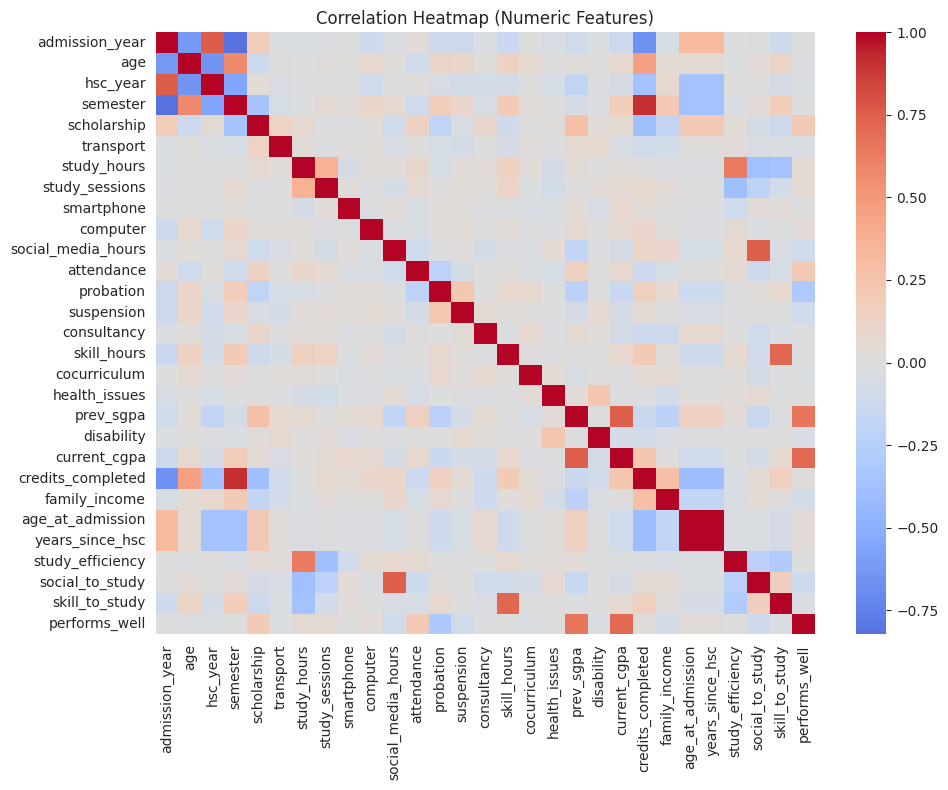

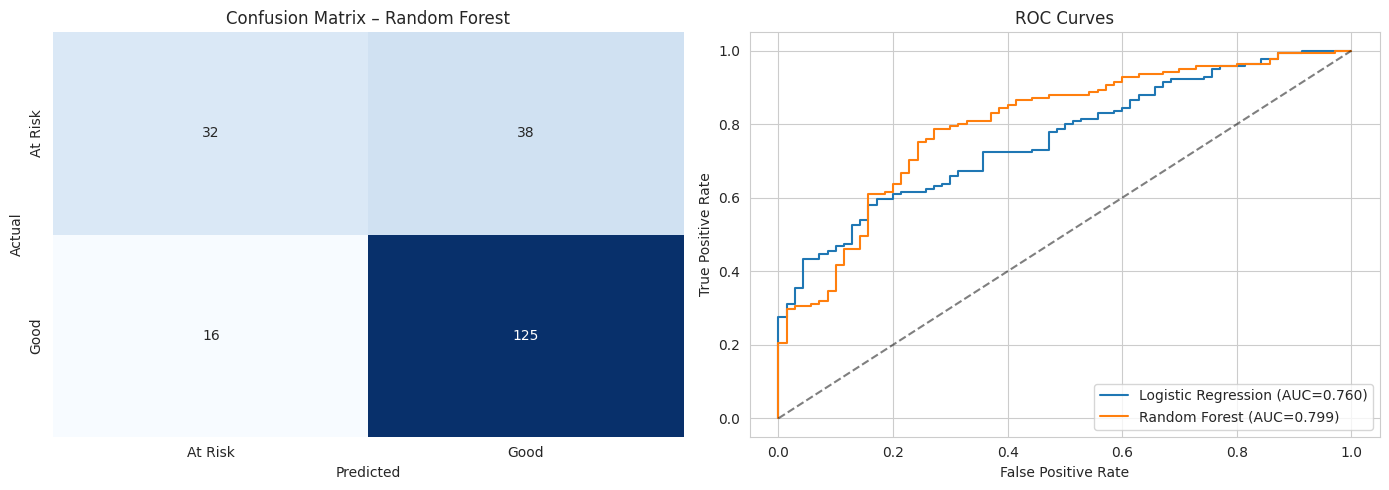

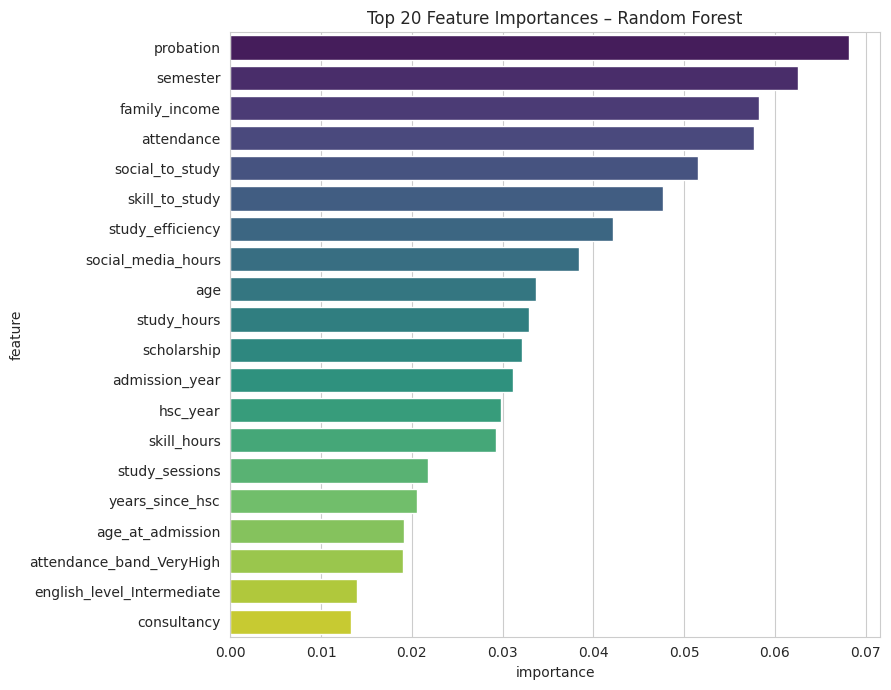

In [40]:
print("\nGenerating plots...")

# 15.1 Target & key numeric distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x=y, ax=axes[0])
axes[0].set_title("Target Distribution")
axes[0].set_xticklabels(['At Risk', 'Good'])

sns.boxplot(data=df, x='performs_well', y='attendance', ax=axes[1])
axes[1].set_title("Attendance vs Performance")
axes[1].set_xticklabels(['At Risk', 'Good'])

sns.boxplot(data=df, x='performs_well', y='study_hours', ax=axes[2])
axes[2].set_title("Daily Study Hours vs Performance")
axes[2].set_xticklabels(['At Risk', 'Good'])
plt.tight_layout()
plt.savefig("eda_plots.png", dpi=150)
plt.show()

# 15.2 Correlation heatmap
plt.figure(figsize=(10, 8))
num_df = df.select_dtypes(include=[np.number])
sns.heatmap(num_df.corr(), annot=False, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

# 15.3 Confusion matrix + ROC curves for both models
plot_confusion_and_roc(fitted_models, X_test, y_test)

# 15.4 Feature importance from Random Forest (top 20)
rf_pipe = fitted_models['Random Forest']
ohe     = rf_pipe.named_steps['prep'].named_transformers_['cat'] \
                  .named_steps['onehot']
cat_names     = ohe.get_feature_names_out(categorical_cols)
feature_names = list(numerical_cols) + list(cat_names)

importances = rf_pipe.named_steps['clf'].feature_importances_
imp_df = (pd.DataFrame({'feature': feature_names, 'importance': importances})
            .sort_values('importance', ascending=False)
            .head(20))
plt.figure(figsize=(9, 7))
sns.barplot(data=imp_df, x='importance', y='feature', palette='viridis')
plt.title("Top 20 Feature Importances – Random Forest")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()


# Saving Output

In [41]:
# saving the cleaned dataset and results
df.to_csv("prepared_student_performance.csv", index=False)
results_df.to_csv("model_results.csv", index=False)
print("\nSaved:  prepared_student_performance.csv")
print("Saved:  model_results.csv")
print("Saved:  eda_plots.png, correlation_heatmap.png, "
      "evaluation_plots.png, feature_importance.png")


Saved:  prepared_student_performance.csv
Saved:  model_results.csv
Saved:  eda_plots.png, correlation_heatmap.png, evaluation_plots.png, feature_importance.png


# Predicting New Student Using Model

In [42]:
# performing prediction on new student
def predict_student(student_dict, model=pipe):
    """Predict performance class for one student record (dict)."""
    row = pd.DataFrame([student_dict])
    for c in X.columns:
        if c not in row.columns:
            row[c] = np.nan
    row = row[X.columns]
    pred  = model.predict(row)[0]
    proba = model.predict_proba(row)[0, 1]
    label = "GOOD PERFORMER" if pred == 1 else "AT RISK"
    return label, round(float(proba), 3)


example_student = {
    'admission_year'     : 2021,
    'gender'             : 'Male',
    'age'                : 21,
    'hsc_year'           : 2020,
    'program'            : 'BCSE',
    'semester'           : 4,
    'scholarship'        : 1,
    'transport'          : 0,
    'study_hours'        : 4,
    'study_sessions'     : 2,
    'learning_mode'      : 'Offline',
    'smartphone'         : 1,
    'computer'           : 1,
    'social_media_hours' : 2,
    'english_level'      : 'Intermediate',
    'attendance'         : 95,
    'probation'          : 0,
    'suspension'         : 0,
    'consultancy'        : 1,
    'skills'             : 'Programming',
    'skill_hours'        : 2,
    'interest_area'      : 'Software',
    'relationship'       : 'Single',
    'cocurriculum'       : 1,
    'living_with'        : 'Family',
    'health_issues'      : 0,
    'disability'         : 0,
    'family_income'      : 45000,
    'age_at_admission'   : 2021 - 2020 - 17,
    'years_since_hsc'    : 1,
    'study_efficiency'   : 4 / 2,
    'social_to_study'    : 2 / (4 + 1),
    'skill_to_study'     : 2 / (4 + 1),
    'attendance_band'    : 'VeryHigh',
}
label, proba = predict_student(example_student)
print("\n" + "=" * 80)
print(" NEW STUDENT PREDICTION")
print("=" * 80)
print(f"Prediction : {label}")
print(f"Probability of good performance: {proba}")

print("\nPipeline finished successfully.")


 NEW STUDENT PREDICTION
Prediction : GOOD PERFORMER
Probability of good performance: 0.869

Pipeline finished successfully.
